# A causal forecast versus Huber on the same observations

**Question:** Can a normal-state predictor detect a balanced recovery shift that Huber reconciliation
misses, and how many false alarms accompany that gain?

Level 3 · Prerequisites: lessons 01–02 and a basic train/calibration/test split. · Reading time: 45 minutes.

## Objectives

Closing a balance and predicting a familiar operating pattern are different tasks. We will actually fit
OreBridge's multichannel histogram gradient boosting predictor, inspect its causal lag construction and
normal calibration, then run it beside the Huber projection on identical numeric observations. A controlled
recovery-relation change preserves conservation while breaking the usual channel relationships. An added
feed-bias example and a healthy control expose the tradeoff between missed disturbances and false alarms.
The comparison is deliberately bounded to three held-out cases; it is not a search for the best detector.

## Setup

Work in a checkout of OreBridge with the notebook environment active. The computational methods live in
`data-pipeline/pipeline`, so the checkout is required; no released OreBridge PyPI distribution is implied.
Install the exact numerical dependencies once, outside this notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Start the kernel with `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` and `MKL_NUM_THREADS=1`.
The setup finds the checkout from the working directory without printing a machine path.

In [1]:
# Use the pinned CPU environment and import the implemented scientific methods.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.learning import fit_normal, lagged, forecast_scores
from pipeline.model.scenarios import generate, channel_specs, conservation_matrix
from pipeline.stages.plant_evaluate import batch_projection, confusion
specs = channel_specs()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Data

OreBridge owns the MIT-licensed authored synthetic generator in
`data-pipeline/pipeline/model/scenarios.py`; [repository](https://github.com/fsantibanezleal/CAOS_OreBridge).
Its sixteen-channel contract is also committed in `data/derived/PL-01/trace.json`. We regenerate the actual
training seeds 100–107, forecast calibration seeds 200–203, and separate state-calibration seeds 300–307.
Test seed 1000 is excluded from every fit and threshold calculation. `data/derived/state-model.json`
documents the canonical model configuration, but this notebook fits the model instead of loading its checkpoint.

## Method

The maintained [scikit-learn implementation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) adds regression trees sequentially to reduce a prediction
loss, with features grouped into histogram bins. OreBridge fits one regressor per channel through a
multi-output wrapper. The actual configuration uses 70 boosting iterations, at most 12 leaves per tree,
64 bins, L2 regularization of 1 and random seed 41. These values come from `learning.fit_normal`, not from a
claim that the configuration has been optimized for an operating mine. The training target is the next
observation; the predictor never receives the injected fault mask.

Its feature vector is $(y_{t-1},y_{t-2},y_{t-3},y_{t-4})$ across all sixteen channels. Each target is
later than every feature. Training records are scaled by their channel standard deviations, and the same
scales are reused at prediction time. Calibration measures absolute errors on disjoint normal sequences;
per-channel thresholds are their higher empirical 99.5th percentiles. The alarm score is
$s_{tj}=|y_{tj}-\hat y_{tj}|/q_j$, so a score above one means a calibrated exceedance, not a posterior
probability of a fault. Execute the fit and inspect its sample counts first.

In [2]:
# Fit the published numerical estimator on normal sequences without test information.
bundle = fit_normal()
print(f"Normal training rows: {bundle['normal_training_rows']}; "
      f"forecast calibration rows: {bundle['calibration_rows']}")
print("Training / forecast calibration seeds:", bundle["train_seeds"],
      "/", bundle["calibration_seeds"])
print(f"Flotation-feed absolute error threshold: {bundle['threshold'][5]:.6f} t/h")
parameters = bundle["model"].estimators_[0].get_params()
print("Fitted estimator configuration:", {k: parameters[k] for k in ["max_iter", "max_leaf_nodes", "max_bins"]})

Normal training rows: 1568; forecast calibration rows: 784
Training / forecast calibration seeds: [100, 101, 102, 103, 104, 105, 106, 107] / [200, 201, 202, 203]
Flotation-feed absolute error threshold: 23.772435 t/h
Fitted estimator configuration: {'max_iter': 70, 'max_leaf_nodes': 12, 'max_bins': 64}


Inspect one design matrix through the imported lag constructor. With 200 observations and four preceding
steps, there are 196 targets and 64 features. The first target is at second four; its four input blocks
refer to seconds three, two, one and zero. This ordering matters when diagnosing leakage: a random split
of overlapping time windows can leak near-duplicates even if a model's API looks innocuous. Here complete
seeded sequences, rather than individual windows, separate fitting and calibration.

In [3]:
# Expose the causal window ordering before scoring a held-out disturbance.
normal_sequence = generate(seed=100, steps=200)
features, targets = lagged(normal_sequence.observed)
print(f"Feature matrix: {features.shape}; target matrix: {targets.shape}")
print("First feed history, newest to oldest, t/h:", np.round(features[0, [0, 16, 32, 48]], 4))
print(f"Following feed observation: {targets[0, 0]:.4f} t/h")

Feature matrix: (196, 64); target matrix: (196, 16)
First feed history, newest to oldest, t/h: [766.6319 748.7098 755.8005 765.56  ]
Following feed observation: 765.9217 t/h


Huber reconciliation asks for an estimate compatible with $Ax=0$ while limiting large-residual influence
([Huber loss](https://doi.org/10.1214/aoms/1177703732)). It has no memory of normal recovery relationships beyond those equations.
To make the input comparison exact, we apply Huber to the very same clock-time vectors used by the
predictor. We calibrate this input convention with normal seeds 300–307; this is an explicitly labeled
same-clock Huber experiment, distinct from the canonical parcel-aligned robust benchmark in lesson 04.
The uncertainty vector is the generator's declared sensor scale. The package performs every robust
projection; the cell only pools its normal scores and selects their empirical quantiles.

Calibration accommodates the ordinary residuals of normal transport transitions. It cannot repair a
mistaken balance model or make a balanced disturbance identifiable. Both methods begin scoring at second
fourteen so they see exactly the same 146 × 16 test entries, and neither threshold is tuned on those entries.

In [4]:
# Calibrate the same-clock Huber residual without using the held-out cases.
matrix = conservation_matrix()
sigma = np.array([s["sigma"] for s in specs])
normal_scores = []
for seed in range(300, 308):
    normal_case = generate(seed=seed)
    scores, _, _ = batch_projection(normal_case.observed[14:], sigma, matrix, robust=True)
    normal_scores.append(scores)
robust_threshold = np.quantile(np.concatenate(normal_scores), 0.995, axis=0, method="higher")
robust_threshold = np.maximum(robust_threshold, 0.1)
print(f"Separate state-calibration rows: {sum(len(x) for x in normal_scores)}")
print(f"Flotation-feed robust score threshold: {robust_threshold[5]:.6f} σ")

Separate state-calibration rows: 1168
Flotation-feed robust score threshold: 6.736266 σ


## Comparison

The generator's `engine` family changes the concentrate/tailings split while preserving each affected
conservation equation. It represents a changed process relation or incompatible fixed engine model, not
a proven defective sensor. We first forecast the held-out observations, keeping prediction, residual score
and known fault label in separate variables. A valid causal model can still miss the onset of an abrupt
change; scoring every affected point, rather than expanding one alarm over an interval, makes that visible.

In [5]:
# Run the fitted causal predictor on new observations and retain every pointwise error.
changed_relation = generate("engine", seed=1000, severity=2)
forecast_score = forecast_scores(bundle, changed_relation.observed)[14:]
test_features, _ = lagged(changed_relation.observed)
forecast = bundle["model"].predict(test_features / np.tile(bundle["scale"], 4)) * bundle["scale"]
forecast = forecast[10:]
truth = changed_relation.fault[14:]
forecast_metrics = confusion(forecast_score > 1, truth)
print(f"HGB: TP={forecast_metrics['tp']}, FP={forecast_metrics['fp']}, FN={forecast_metrics['fn']}")
print(f"Recall: {forecast_metrics['recall']:.6f}; "
      f"false-positive rate: {forecast_metrics['false_positive_rate']:.6f}")

HGB: TP=291, FP=19, FN=9
Recall: 0.970000; false-positive rate: 0.009332


Run the implemented batch Huber projection on those exact observations, with the previously fixed normal
thresholds. To isolate the reason conservation is weak here, regenerate the healthy counterpart with the
same seed. Subtracting it cancels the same random measurement noise and reveals the injected change alone.
If its product with the conservation matrix is zero, the changed operating relation lies in the balance's
null space: no amount of exact balance closure can distinguish it from another balanced state.

In [6]:
# Hold input values fixed and measure the conservation-null disturbance explicitly.
robust_score, robust_state, robust_iterations = batch_projection(
    changed_relation.observed[14:], sigma, matrix, robust=True
)
robust_metrics = confusion(robust_score > robust_threshold, truth)
healthy_counterpart = generate("healthy", seed=1000, severity=2)
injected_change = changed_relation.observed - healthy_counterpart.observed
print(f"Huber: TP={robust_metrics['tp']}, FP={robust_metrics['fp']}, FN={robust_metrics['fn']}")
print(f"Recall: {robust_metrics['recall']:.6f}; "
      f"false-positive rate: {robust_metrics['false_positive_rate']:.6f}")
print(f"Largest factor response to the injected shift: {np.max(np.abs(injected_change @ matrix.T)):.12f}")

Huber: TP=0, FP=4, FN=300
Recall: 0.000000; false-positive rate: 0.001965
Largest factor response to the injected shift: 0.000000000000


Focus on concentrate solids to see the changed relationship in engineering units, then compare normalized
alarm scores for that same channel. A Huber score is divided by its own calibrated threshold, so both
horizontal lines have an exceedance level of one. This scale convention makes the alarm rule comparable;
it does not make the underlying loss functions, information sources or score distributions equivalent.

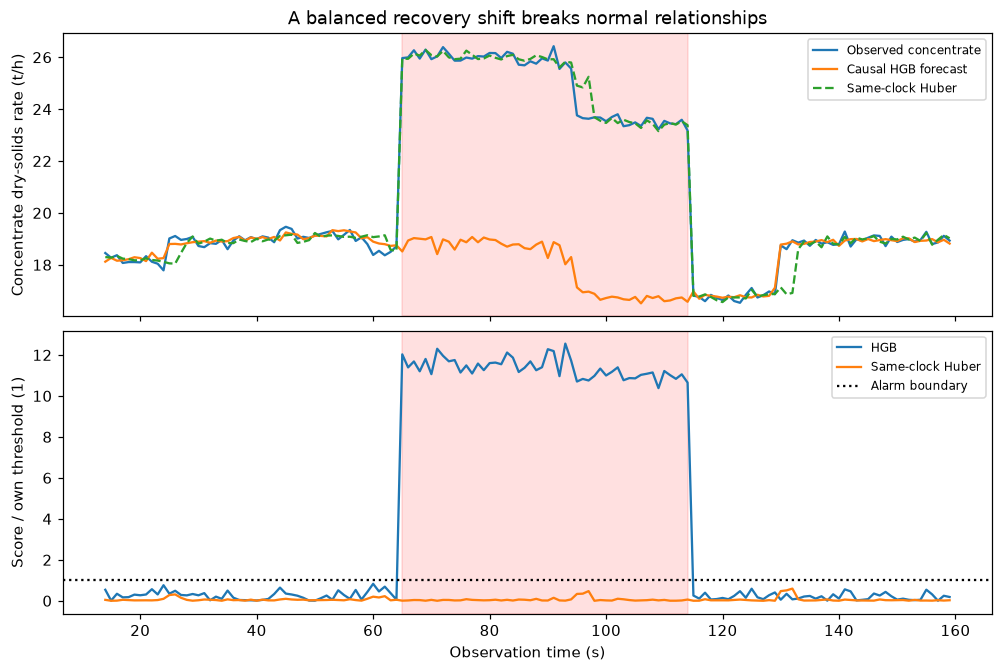

In [7]:
# Show the same concentrate observations, two estimates and their own calibrated scores.
time_s = np.arange(14, 160)
channel = 6
fig, axes = plt.subplots(2, 1, figsize=(9, 6), layout="constrained", sharex=True)
axes[0].plot(time_s, changed_relation.observed[14:, channel], label="Observed concentrate")
axes[0].plot(time_s, forecast[:, channel], label="Causal HGB forecast")
axes[0].plot(time_s, robust_state[:, channel], linestyle="--", label="Same-clock Huber")
axes[0].set(title="A balanced recovery shift breaks normal relationships", ylabel="Concentrate dry-solids rate (t/h)")
axes[1].plot(time_s, forecast_score[:, channel], label="HGB")
axes[1].plot(time_s, robust_score[:, channel] / robust_threshold[channel], label="Same-clock Huber")
axes[1].axhline(1, color="black", linestyle=":", label="Alarm boundary")
axes[1].set(xlabel="Observation time (s)", ylabel="Score / own threshold (1)")
for axis in axes:
    axis.axvspan(65, 114, alpha=0.12, color="red")
    axis.legend(fontsize=8)
plt.show()

The concentrate reading departs from the predictor's usual relationship with the other channels, while a
conservation-compatible Huber state can remain near the changed observation. The score panel reveals why
the methods disagree: the predictor asks whether this observation was expected from preceding multichannel
history; reconciliation asks how far it must move to close the admitted factors. The red interval marks
truth for interpretation only and never enters either inference. A larger forecast score does not establish
whether the process, the instrument, or the fixed relation has changed.

Now add a direct feed bias and a healthy control without changing fitted models or thresholds. Pooling only
the recovery-shift example would hide the alert burden. Precision is undefined when no alarm is raised;
recall is undefined when no fault exists. The imported confusion calculation returns null in those cases.
We preserve that value instead of treating a healthy-control recall as either perfect or zero.

In [8]:
# Keep held-out controls and every false alarm in the comparison.
comparisons = {"engine": {"HGB": forecast_metrics, "Huber": robust_metrics}}
for family in ["bias", "healthy"]:
    case = generate(family, seed=1000, severity=2)
    predicted = forecast_scores(bundle, case.observed)[14:]
    projected, _, _ = batch_projection(case.observed[14:], sigma, matrix, robust=True)
    comparisons[family] = {
        "HGB": confusion(predicted > 1, case.fault[14:]),
        "Huber": confusion(projected > robust_threshold, case.fault[14:]),
    }
family_names = {"engine": "Recovery shift", "bias": "Feed bias", "healthy": "Healthy control"}
for family, methods in comparisons.items():
    for method, metrics in methods.items():
        recall_text = "null (undefined)" if metrics["recall"] is None else f"{metrics['recall']:.6f}"
        print(f"{family_names[family]} / {method}: recall={recall_text}; false alarms={metrics['fp']}")

Recovery shift / HGB: recall=0.970000; false alarms=19
Recovery shift / Huber: recall=0.000000; false alarms=4
Feed bias / HGB: recall=1.000000; false alarms=62
Feed bias / Huber: recall=0.700000; false alarms=4
Healthy control / HGB: recall=null (undefined); false alarms=9
Healthy control / Huber: recall=null (undefined); false alarms=4


Compare recall only where a disturbance denominator exists and show false-positive rates for all three
cases. The two panels use percentages but have different denominators: affected channel-time entries for
recall, unaffected entries for false positives. Counting either quantity at event level would answer a
different question. The small number of cases supports a mechanistic lesson, not a confidence interval
for an industrial fleet or a claim of broad superiority.

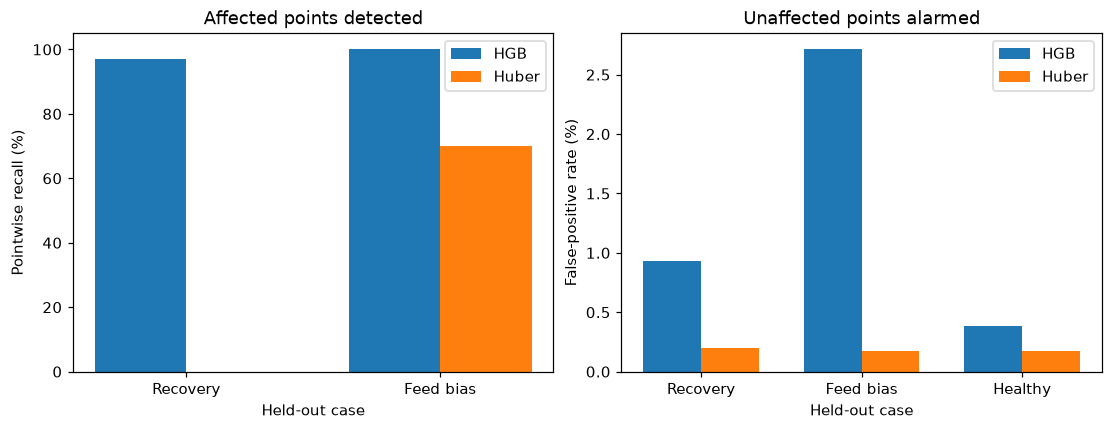

In [9]:
# Make detection gains and false-alert costs visible with their distinct denominators.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for offset, method in [(-0.18, "HGB"), (0.18, "Huber")]:
    recalls = [100 * comparisons[f][method]["recall"] for f in ["engine", "bias"]]
    false_rates = [100 * comparisons[f][method]["false_positive_rate"] for f in comparisons]
    axes[0].bar(np.arange(2) + offset, recalls, 0.36, label=method)
    axes[1].bar(np.arange(3) + offset, false_rates, 0.36, label=method)
axes[0].set_xticks([0, 1], ["Recovery", "Feed bias"])
axes[1].set_xticks([0, 1, 2], ["Recovery", "Feed bias", "Healthy"])
axes[0].set(title="Affected points detected", ylabel="Pointwise recall (%)", xlabel="Held-out case")
axes[1].set(title="Unaffected points alarmed", ylabel="False-positive rate (%)", xlabel="Held-out case")
for axis in axes:
    axis.legend()
plt.show()

The predictor detects more of both injected disturbances in this comparison, but it also alarms more often
on unaffected channel-time entries. The healthy-control panel is essential: no recall exists there, yet
nuisance alerts remain measurable. Same-clock Huber thresholds absorb some normal transport variation,
which can lower both false alarms and sensitivity. This observation should motivate a physically justified
time model, not test-driven threshold adjustment. The next notebook returns to the canonical parcel-aligned
evaluation and measures its full timing, engine and topology ablations.

Published graph-based anomaly forecasting already learns sensor relationships: [GDN](https://arxiv.org/abs/2106.06947)
is relevant prior work. We have not implemented or run GDN here, and the histogram predictor is not renamed
as a graph network. The executed published components are scikit-learn's histogram boosting and the Huber
loss implemented by OreBridge's robust projection. This distinction prevents a citation from becoming an
unearned experimental comparison.

## Results

**Answer:** The fitted model uses 1568 normal training rows and 784 forecast-calibration rows. On the balanced
recovery shift it detects 291 of 300 affected points (97.000000% recall), while same-clock Huber detects
0 of 300. The predictor raises 19 false alarms versus Huber's 4 in that case. For the feed bias their recalls
are 100.000000% and 70.000000%; on the healthy control their false-alarm counts are 9 and 4, with null recall.
The gain therefore comes with a measurable alert cost and a narrower question than identifying a failed sensor.

A predictor's surprise can reveal a balance-preserving change because its training supplies additional
statistical structure. It can also flag unfamiliar healthy behavior. This experiment uses finite, valid
observations throughout; missing values, source timestamp rejection and model compatibility require the
explicit treatment in the final lesson.

## Summary

The two algorithms disagree for an intelligible reason: they encode different knowledge. Causal normal-state
prediction constrains expected relationships; Huber reconciliation constrains admitted conservation equations.
We fitted, calibrated and ran them without future inputs or test thresholds, using the same test values.
A balanced process change can defeat a balance residual even when that residual is computed perfectly.

## References

- scikit-learn, `HistGradientBoostingRegressor`, exact installed version 1.9.1: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- Huber (1964), *Robust Estimation of a Location Parameter*: https://doi.org/10.1214/aoms/1177703732
- Deng and Hooi (2021), *Graph Neural Network-Based Anomaly Detection in Multivariate Time Series*,
  cited as prior work, not an executed comparator: https://arxiv.org/abs/2106.06947
- Executed code: `data-pipeline/pipeline/model/learning.py` and
  `data-pipeline/pipeline/stages/plant_evaluate.py`; canonical model manifest: `data/derived/state-model.json`.